# 03. Подбор модели на validation

Вариант 6. Выполняйте блокноты в порядке 01 → 02 → 03 → 04. Код этапа взят из scripts.

Период данных: 2016–2025; отличие от требуемого 2010–2025 необходимо согласовать с преподавателем.

In [1]:
from pathlib import Path
import subprocess
import sys
import os

project = Path("/content/fintech_nbk_corrected")

if not (project / ".git").exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/BEJLIKAN/fintech-nbk-rates.git",
            str(project)
        ],
        check=True
    )

os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import numpy as np
import pandas as pd
import scipy
import statsmodels.api as sm
import sklearn
import matplotlib.pyplot as plt

%matplotlib inline

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Statsmodels:", sm.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Среда готова — можно запускать вторую ячейку.")


NumPy: 2.1.3
Pandas: 2.2.3
SciPy: 1.16.3
Statsmodels: 0.15.0
Scikit-learn: 1.6.1
Среда готова — можно запускать вторую ячейку.


Библиотеки подключены
Проверено: 120 последовательных месяцев
Для разработки доступны train и validation.
Test отложен до четвёртого этапа.
Юридические лица | Train: 79 | Validation: 17 | Признаков: 16
Физические лица, включая ИП | Train: 79 | Validation: 17 | Признаков: 16
Регрессии и прогноз «без изменения ставки» готовы
Подготовлено 4 варианта параметров
Юридические лица — обучение завершено
Физические лица, включая ИП — обучение завершено


,group,candidate,num_leaves,max_depth,min_child_samples,best_iteration,validation_rmse
2,business,3,5,3,15,11,0.3633
1,business,2,4,2,20,22,0.3636
3,business,4,7,3,20,22,0.3636
0,business,1,3,2,15,12,0.3654
6,households,3,5,3,15,182,1.6179
4,households,1,3,2,15,161,1.6307
5,households,2,4,2,20,41,1.6615
7,households,4,7,3,20,41,1.6615


,group,model,RMSE,MAE,R2
3,business,lightgbm,0.3633,0.2888,-0.0039
0,business,zero_change,0.3681,0.2949,-0.0307
2,business,asymmetric,0.4130,0.3159,-0.2978
1,business,symmetric,0.4269,0.3247,-0.3864
7,households,lightgbm,1.6179,1.2148,0.0547
4,households,zero_change,1.6737,1.2036,-0.0116
5,households,symmetric,1.7122,1.3397,-0.0586
6,households,asymmetric,1.7140,1.3550,-0.0608


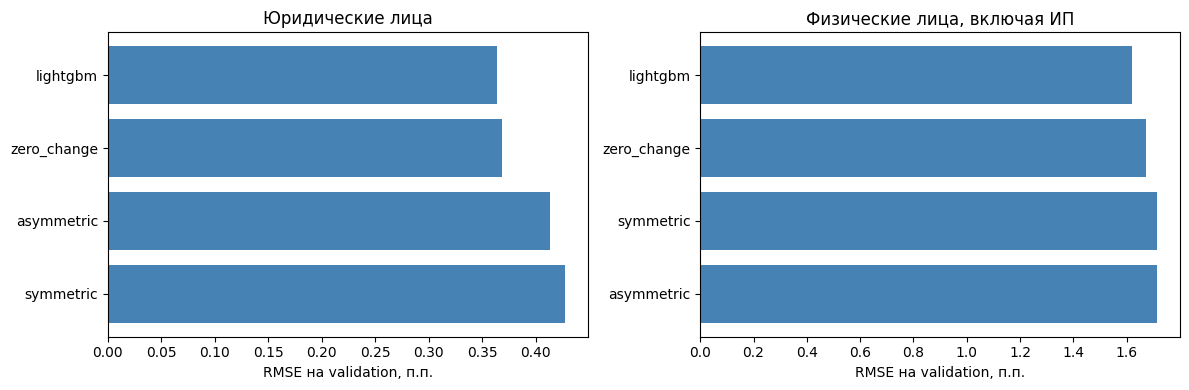

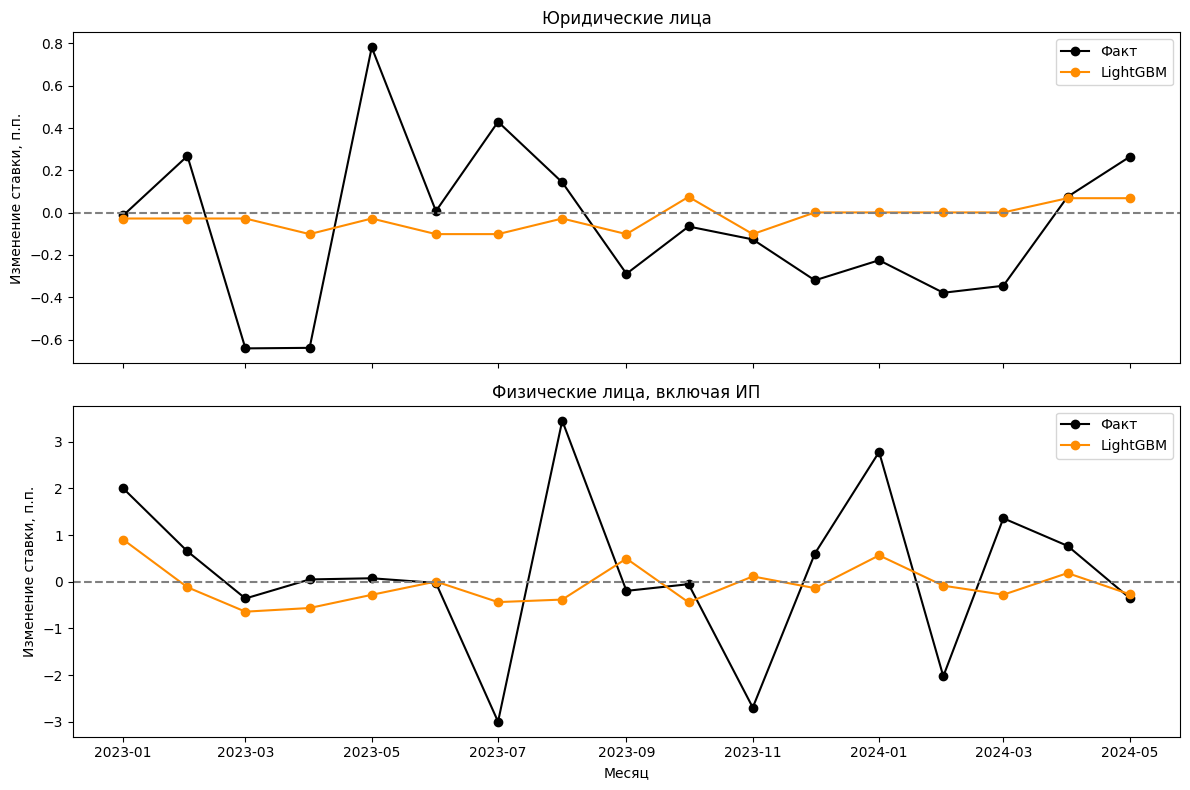

Юридические лица — выбранная модель: lightgbm
Физические лица, включая ИП — выбранная модель: lightgbm
Модели, параметры и таблицы сохранены
Архив: /content/fintech_nbk_corrected/results/reproduced/stage3_results.zip


In [2]:
from src.train import fit_baseline
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    raise RuntimeError("Сначала скачайте весь репозиторий и перейдите в его папку")
sys.path.insert(0, str(ROOT))
WORK = ROOT / "results/reproduced"
WORK.mkdir(parents=True, exist_ok=True)


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import lightgbm as lgb
import yaml
import joblib

from pathlib import Path
from IPython.display import display
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

RANDOM_STATE = 42
FEATURE_LAG = 2

print("Библиотеки подключены")

data_path = (ROOT / "data/NBK_BNS_variant6_2016_2025.csv")

assert data_path.exists(), "Проверь название загруженного CSV."

data = pd.read_csv(data_path, encoding="utf-8-sig")

data["month"] = pd.to_datetime(
    data["month"], format="%Y-%m", errors="raise"
)

data = data.sort_values("month").reset_index(drop=True)

numeric_columns = data.columns.drop("month")

data[numeric_columns] = data[numeric_columns].apply(
    pd.to_numeric, errors="raise"
)

assert np.isfinite(data[numeric_columns].to_numpy()).all()

assert pd.DatetimeIndex(data["month"]).equals(
    pd.date_range("2016-01-01", "2025-12-01", freq="MS")
)

print("Проверено: 120 последовательных месяцев")

TRAIN_END = pd.Timestamp("2022-12-01")
VALID_END = pd.Timestamp("2024-06-01")

development = data[data["month"] <= VALID_END].copy()
test_locked = data[data["month"] > VALID_END].copy()

targets = {
    "business": "Y_business_change_pp",
    "households": "Y_households_change_pp",
}

group_names = {
    "business": "Юридические лица",
    "households": "Физические лица, включая ИП",
}

assert len(development) == 102
assert len(test_locked) == 18

print("Для разработки доступны train и validation.")
print("Test отложен до четвёртого этапа.")

from src.features import make_macro_features

from src.features import make_features

datasets = {}

for group, target in targets.items():
    X = make_features(development, group, FEATURE_LAG)
    usable = X.notna().all(axis=1)

    train_mask = (
        usable
        & (development["month"] <= pd.Timestamp("2022-11-01"))
    )

    valid_mask = (
        usable
        & (development["month"] > TRAIN_END)
        & (development["month"] <= pd.Timestamp("2024-05-01"))
    )

    datasets[group] = {
        "X_train": X.loc[train_mask].copy(),
        "y_train": development.loc[train_mask, target].copy(),
        "X_valid": X.loc[valid_mask].copy(),
        "y_valid": development.loc[valid_mask, target].copy(),
        "dates_valid": development.loc[valid_mask, "month"].copy(),
    }

    assert train_mask.sum() == 79
    assert valid_mask.sum() == 17

    print(
        group_names[group],
        "| Train:", train_mask.sum(),
        "| Validation:", valid_mask.sum(),
        "| Признаков:", X.shape[1]
    )

baseline_columns = {
    "symmetric": [
        "loan_change_lag2",
        "base_change_lag2",
        "inflation_change_lag2",
    ],
    "asymmetric": [
        "loan_change_lag2",
        "base_change_lag2",
        "inflation_up_lag2",
        "inflation_down_lag2",
    ],
}

baseline_models = {}
predictions = {}

for group, parts in datasets.items():
    baseline_models[group] = {}

    predictions[group] = {
        "zero_change": np.zeros(len(parts["y_valid"]))
    }

    for name, columns in baseline_columns.items():
        X_train = sm.add_constant(
            parts["X_train"][columns],
            has_constant="add"
        )
        X_valid = sm.add_constant(
            parts["X_valid"][columns],
            has_constant="add"
        )

        assert np.linalg.matrix_rank(
            X_train.to_numpy()
        ) == X_train.shape[1]

        model = fit_baseline(parts['y_train'], X_train)

        baseline_models[group][name] = model
        predictions[group][name] = model.predict(X_valid)

print("Регрессии и прогноз «без изменения ставки» готовы")

parameter_candidates = [
    {"num_leaves": 3, "max_depth": 2, "min_child_samples": 15},
    {"num_leaves": 4, "max_depth": 2, "min_child_samples": 20},
    {"num_leaves": 5, "max_depth": 3, "min_child_samples": 15},
    {"num_leaves": 7, "max_depth": 3, "min_child_samples": 20},
]

common_params = {
    "objective": "regression",
    "metric": "rmse",
    "n_estimators": 1000,
    "learning_rate": 0.03,
    "reg_lambda": 1.0,
    "random_state": RANDOM_STATE,
    "n_jobs": 1,
    "verbosity": -1,
    "deterministic": True,
    "force_col_wise": True,
    "importance_type": "gain",
}

print("Подготовлено 4 варианта параметров")

boosting_models = {}
best_settings = {}
search_rows = []

for group, parts in datasets.items():
    best_rmse = np.inf

    for number, candidate in enumerate(parameter_candidates, start=1):
        model = lgb.LGBMRegressor(
            **common_params,
            **candidate
        )

        model.fit(
            parts["X_train"],
            parts["y_train"],
            eval_set=[(parts["X_valid"], parts["y_valid"])],
            eval_metric="rmse",
            callbacks=[
                lgb.early_stopping(
                    stopping_rounds=50,
                    first_metric_only=True,
                    verbose=False
                )
            ]
        )

        prediction = model.predict(
            parts["X_valid"],
            num_iteration=model.best_iteration_
        )

        rmse = float(np.sqrt(
            mean_squared_error(parts["y_valid"], prediction)
        ))

        search_rows.append({
            "group": group,
            "candidate": number,
            **candidate,
            "best_iteration": int(model.best_iteration_),
            "validation_rmse": rmse,
        })

        if rmse < best_rmse:
            best_rmse = rmse
            boosting_models[group] = model
            predictions[group]["lightgbm"] = prediction

            best_settings[group] = {
                **candidate,
                "best_iteration": int(model.best_iteration_),
                "validation_rmse": rmse,
            }

    print(group_names[group], "— обучение завершено")

search_results = pd.DataFrame(search_rows)

display(
    search_results
    .sort_values(["group", "validation_rmse"])
    .round(4)
)

comparison_rows = []

for group, parts in datasets.items():
    for name, prediction in predictions[group].items():
        comparison_rows.append({
            "group": group,
            "model": name,
            "RMSE": float(np.sqrt(
                mean_squared_error(parts["y_valid"], prediction)
            )),
            "MAE": float(mean_absolute_error(
                parts["y_valid"], prediction
            )),
            "R2": float(r2_score(
                parts["y_valid"], prediction
            )),
        })

comparison = pd.DataFrame(comparison_rows)

display(
    comparison
    .sort_values(["group", "RMSE"])
    .round(4)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, group in zip(axes, targets):
    table = (
        comparison[comparison["group"] == group]
        .sort_values("RMSE")
    )

    ax.barh(
        table["model"],
        table["RMSE"],
        color="steelblue"
    )
    ax.invert_yaxis()
    ax.set_title(group_names[group])
    ax.set_xlabel("RMSE на validation, п.п.")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for ax, group in zip(axes, targets):
    parts = datasets[group]

    ax.plot(
        parts["dates_valid"],
        parts["y_valid"],
        color="black",
        marker="o",
        label="Факт"
    )

    ax.plot(
        parts["dates_valid"],
        predictions[group]["lightgbm"],
        color="darkorange",
        marker="o",
        label="LightGBM"
    )

    ax.axhline(0, color="gray", linestyle="--")
    ax.set_title(group_names[group])
    ax.set_ylabel("Изменение ставки, п.п.")
    ax.legend()

axes[1].set_xlabel("Месяц")

plt.tight_layout()
plt.show()

selected_models = {}

for group in targets:
    winner = (
        comparison[comparison["group"] == group]
        .sort_values("RMSE", kind="stable")
        .iloc[0]
    )

    selected_models[group] = str(winner["model"])

    print(
        group_names[group],
        "— выбранная модель:",
        winner["model"]
    )

config = {
    "variant": 6,
    "random_state": RANDOM_STATE,
    "feature_lag_months": FEATURE_LAG,
    "availability_assumption": (
        "Forecast at month start using t-2 or older data; "
        "publication dates not yet verified."
    ),
    "train_end": "2022-11-01",
    "validation_start": "2023-01-01",
    "validation_fit_end": "2024-05-01",
    "validation_end": "2024-06-01",
    "test_start": "2024-07-01",
    "test_used": False,
    "selection_metric": "validation_RMSE",
    "refit_before_test": False,
    "selected_models": selected_models,
    "baseline_columns": baseline_columns,
    "lightgbm_common_params": common_params,
    "parameter_candidates": parameter_candidates,
    "lightgbm_selected": best_settings,
    "feature_columns": list(
        datasets["business"]["X_train"].columns
    ),
}

output_dir = (WORK / "stage3_results")
output_dir.mkdir(exist_ok=True)

with open(output_dir / "config.yaml", "w", encoding="utf-8") as file:
    yaml.safe_dump(
        config, file,
        allow_unicode=True,
        sort_keys=False
    )

comparison.to_csv(
    output_dir / "validation_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

search_results.to_csv(
    output_dir / "parameter_search.csv",
    index=False,
    encoding="utf-8-sig"
)

joblib.dump(
    {
        "baseline_models": baseline_models,
        "boosting_models": boosting_models,
        "config": config,
    },
    output_dir / "stage3_models.joblib"
)

print("Модели, параметры и таблицы сохранены")

import importlib.metadata
import shutil


packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "statsmodels",
    "scikit-learn",
    "lightgbm",
    "PyYAML",
    "joblib",
]

requirements = "\n".join(
    f"{package}=={importlib.metadata.version(package)}"
    for package in packages
)

(output_dir / "requirements_stage3.txt").write_text(
    requirements + "\n",
    encoding="utf-8"
)

archive = shutil.make_archive(
    str(WORK / "stage3_results"),
    "zip",
    root_dir=output_dir
)

print("Архив:", archive)
